In [ ]:
import torch
from functools import partial
from time import time
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
from marinade.gotm.tridiagonal import tridiagonal_solve, random_tridiag_dd

In [ ]:
def tridiagonal_sum_backward(*args, **kwargs):
    z = tridiagonal_solve(*args, **kwargs)
    s = z.sum()
    s.backward()

In [ ]:
def time_func(f, use_cuda=False, n_runs=20, warm_runs=1):
    t = []
    for i in range(n_runs + warm_runs):
        if use_cuda:
            assert torch.cuda.is_available()
            # Create CUDA events
            start_event = torch.cuda.Event(enable_timing=True)
            end_event = torch.cuda.Event(enable_timing=True)

            start_event.record()
            f()
            end_event.record()
            torch.cuda.synchronize()
            next_t = start_event.elapsed_time(end_event) / 1000  # ms -> s
        else:
            start_time = time()
            f()
            next_t = time() - start_time
        if i >= warm_runs:
            t.append(next_t)

    return torch.tensor(t, dtype=torch.float64).mean().item()     
    

In [ ]:
def benchmark_tridiag(
        n_rows_all=None,
        n_batch_all=None,
        use_cuda=False,
        cuda_device_idx=0,
        dtype=None,
        n_runs=100,
        warm_runs=3,
        ):    
    device = torch.device(f'cuda:{cuda_device_idx}') if use_cuda else 'cpu'

    dtype = (torch.float32 if use_cuda else torch.float64) if dtype is None else dtype
    s = (len(n_rows_all), len(n_batch_all))
    #initialize arrays to store timing results
    t_nograd_ex_thomas, t_nograd_im_thomas, t_grad_ex_thomas, t_grad_im_thomas, t_fb_ex_thomas, t_fb_im_thomas = \
        torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64), \
            torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64)
    t_nograd_ex_paracr, t_nograd_im_paracr, t_grad_ex_paracr, t_grad_im_paracr, t_fb_ex_paracr, t_fb_im_paracr = \
        torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64), \
            torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64), torch.empty(s, dtype=torch.float64)
    dd = partial(random_tridiag_dd, device=device, dtype=dtype)

    for i, n_rows in enumerate(tqdm(n_rows_all)):
        for j, n_batch in enumerate(tqdm(n_batch_all, leave=False)):
            a,b,c,y = dd(requires_grad=False, n_rows=n_rows, n_batch=n_batch)  # generate data

            # measure forward pass without gradient tracking
            f_im_thomas = partial(tridiagonal_solve, a, b, c, y, method='thomas', implicit_backward=True)
            f_im_paracr = partial(tridiagonal_solve, a, b, c, y, method='paracr', implicit_backward=True)
            f_ex_thomas = partial(tridiagonal_solve, a, b, c, y, method='thomas', implicit_backward=False)
            f_ex_paracr = partial(tridiagonal_solve, a, b, c, y, method='paracr', implicit_backward=False)
            t_nograd_ex_thomas[i, j] = time_func(f_ex_thomas, n_runs=n_runs, warm_runs=warm_runs)
            t_nograd_ex_paracr[i, j] = time_func(f_ex_paracr, n_runs=n_runs, warm_runs=warm_runs)
            t_nograd_im_thomas[i, j] = time_func(f_im_thomas, n_runs=n_runs, warm_runs=warm_runs)
            t_nograd_im_paracr[i, j] = time_func(f_im_paracr, n_runs=n_runs, warm_runs=warm_runs)

            # measure forward pass with gradient tracking
            a.requires_grad = b.requires_grad = c.requires_grad = y.requires_grad = True
            t_grad_ex_thomas[i, j] = time_func(f_ex_thomas, n_runs=n_runs, warm_runs=warm_runs)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_grad_ex_paracr[i, j] = time_func(f_ex_paracr, n_runs=n_runs, warm_runs=warm_runs)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_grad_im_thomas[i, j] = time_func(f_im_thomas, n_runs=n_runs, warm_runs=warm_runs)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_grad_im_paracr[i, j] = time_func(f_im_paracr, n_runs=n_runs, warm_runs=warm_runs)
            
            # measure forward and backward passes together with gradient tracking
            g_im_thomas = partial(tridiagonal_sum_backward, a, b, c, y, method='thomas', implicit_backward=True)
            g_im_paracr = partial(tridiagonal_sum_backward, a, b, c, y, method='paracr', implicit_backward=True)
            g_ex_thomas = partial(tridiagonal_sum_backward, a, b, c, y, method='thomas', implicit_backward=False)
            g_ex_paracr = partial(tridiagonal_sum_backward, a, b, c, y, method='paracr', implicit_backward=False)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_fb_im_thomas[i, j] = time_func(g_im_thomas, n_runs=n_runs, warm_runs=warm_runs)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_fb_im_paracr[i, j] = time_func(g_im_paracr, n_runs=n_runs, warm_runs=warm_runs)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_fb_ex_thomas[i, j] = time_func(g_ex_thomas, n_runs=n_runs, warm_runs=warm_runs)
            a.grad, b.grad, c.grad, y.grad = None, None, None, None
            t_fb_ex_paracr[i, j] = time_func(g_ex_paracr, n_runs=n_runs, warm_runs=warm_runs)
    t_back_im_thomas, t_back_ex_thomas = t_fb_im_thomas - t_grad_im_thomas, t_fb_ex_thomas - t_grad_ex_thomas
    t_back_im_paracr, t_back_ex_paracr = t_fb_im_paracr - t_grad_im_paracr, t_fb_ex_paracr - t_grad_ex_paracr

    return t_nograd_ex_thomas, t_nograd_im_thomas, t_grad_ex_thomas, t_grad_im_thomas, t_back_im_thomas, t_back_ex_thomas, t_nograd_ex_paracr, t_nograd_im_paracr, t_grad_ex_paracr, t_grad_im_paracr, t_back_im_paracr, t_back_ex_paracr

In [ ]:
n_rows_all = [16, 32, 64, 128]
n_batch_all = [1, 2, 16, 32]

t_nograd_ex_thomas, t_nograd_im_thomas, t_grad_ex_thomas, t_grad_im_thomas, t_back_im_thomas, t_back_ex_thomas, t_nograd_ex_paracr, t_nograd_im_paracr, t_grad_ex_paracr, t_grad_im_paracr, t_back_im_paracr, t_back_ex_paracr = \
    benchmark_tridiag(n_rows_all=n_rows_all, n_batch_all=n_batch_all, use_cuda = False)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

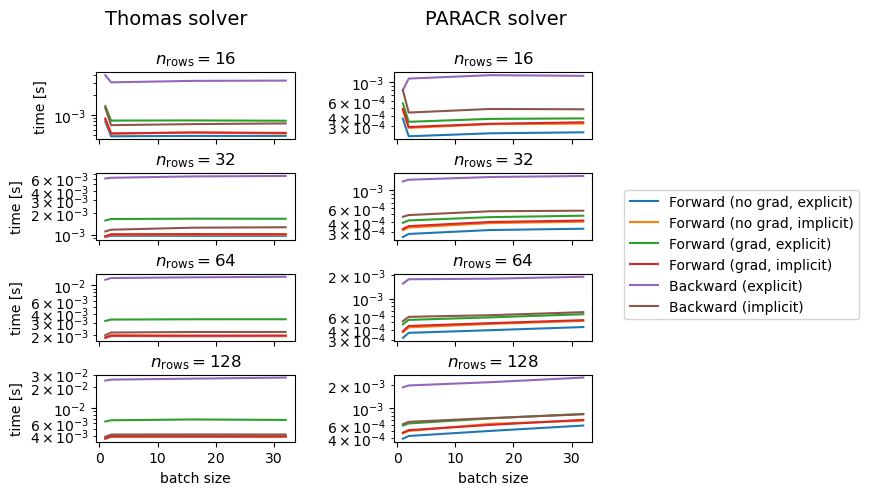

In [ ]:
f, ax = plt.subplots(len(n_rows_all), 2, sharex=True)
for i, n_rows in enumerate(n_rows_all):
    ax[i, 0].plot(n_batch_all, t_nograd_ex_thomas[i,:], label='Forward (no grad, explicit)')
    ax[i, 0].plot(n_batch_all, t_nograd_im_thomas[i,:], label='Forward (no grad, implicit)')
    ax[i, 0].plot(n_batch_all, t_grad_ex_thomas[i,:], label='Forward (grad, explicit)')
    ax[i, 0].plot(n_batch_all, t_grad_im_thomas[i,:], label='Forward (grad, implicit)')
    ax[i, 0].plot(n_batch_all, t_back_ex_thomas[i,:], label='Backward (explicit)')
    ax[i, 0].plot(n_batch_all, t_back_im_thomas[i,:], label='Backward (implicit)')
    tstr = f'$n_\\text{{rows}} = {n_rows}$'
    ax[i, 0].set_title(tstr)
    ax[i, 0].set_ylabel('time [s]')
    # if i == 0:
    #     ax[i, 0].legend()
ax[-1, 0].set_xlabel('batch size')
for i, n_rows in enumerate(n_rows_all):
    ax[i, 1].plot(n_batch_all, t_nograd_ex_paracr[i,:], label='Forward (no grad, explicit)')
    ax[i, 1].plot(n_batch_all, t_nograd_im_paracr[i,:], label='Forward (no grad, implicit)')
    ax[i, 1].plot(n_batch_all, t_grad_ex_paracr[i,:], label='Forward (grad, explicit)')
    ax[i, 1].plot(n_batch_all, t_grad_im_paracr[i,:], label='Forward (grad, implicit)')
    ax[i, 1].plot(n_batch_all, t_back_ex_paracr[i,:], label='Backward (explicit)')
    ax[i, 1].plot(n_batch_all, t_back_im_paracr[i,:], label='Backward (implicit)')
    tstr = f'$n_\\text{{rows}} = {n_rows}$'
    ax[i, 1].set_title(tstr)
    # ax[i, 1].set_ylabel('time [s]')
ax[-1, 1].set_xlabel('batch size')

f.text(0.25, 0.98, "Thomas solver", ha="center", fontsize=14)
f.text(0.75, 0.98, "PARACR solver", ha="center", fontsize=14)

handles, labels = ax[0, 0].get_legend_handles_labels()

for _ax in ax.flat:
    _ax.set_yscale('log')

f.legend(
    handles, labels,
    loc="center left",
    bbox_to_anchor=(0.95, 0.5),
    borderaxespad=0,
)
f.subplots_adjust(hspace=0.5, wspace=0.5); plt.show()